# Preprocessing and Baseline Segmentation

In [3]:
# Imports

import numpy as np
import h5py
import matplotlib.pyplot as plt
from pathlib import Path
from collections import defaultdict
from sklearn.model_selection import train_test_split
from scipy.ndimage import gaussian_filter

print("Imports successful")

Imports successful


# Loading All Slices

In [4]:

DATA_DIR = Path("data/raw/BraTS2020_training_data")

# Get all .h5 files
h5_files = sorted(DATA_DIR.glob("*.h5"))

print("Total .h5 files found:", len(h5_files))
print("Example file:", h5_files[0].name)

Total .h5 files found: 57195
Example file: volume_100_slice_0.h5


# Grouping the Slice Files By Volume

In [5]:
# Grouping slice files by volume
volume_to_files = defaultdict(list)

for f in h5_files:
    parts = f.stem.split("_")  
    volume_id = f"{parts[0]}_{parts[1]}"
    volume_to_files[volume_id].append(f)

# Sorting slice files
for volume_id in volume_to_files:
    volume_to_files[volume_id] = sorted(
        volume_to_files[volume_id],
        key=lambda x: int(x.stem.split("_")[-1])
    )

print("Total unique volumes:", len(volume_to_files))
print("Example volume IDs:", list(volume_to_files.keys())[:5])

Total unique volumes: 369
Example volume IDs: ['volume_100', 'volume_101', 'volume_102', 'volume_103', 'volume_104']


# Choosing Our Subset of Volumes to Use 

In [ ]:
# Starting with 10 for now until more comfortable with complete pipeline
# u-net model used way less cuz length of runtime
selected_volumes = list(volume_to_files.keys())[:30]

subset_files = []
for vol in selected_volumes:
    subset_files.extend(volume_to_files[vol])

print("Selected volumes:", selected_volumes)
print("Total files in subset:", len(subset_files))

Selected volumes: ['volume_100', 'volume_101', 'volume_102', 'volume_103', 'volume_104', 'volume_105', 'volume_106', 'volume_107', 'volume_108', 'volume_109', 'volume_10', 'volume_110', 'volume_111', 'volume_112', 'volume_113', 'volume_114', 'volume_115', 'volume_116', 'volume_117', 'volume_118', 'volume_119', 'volume_11', 'volume_120', 'volume_121', 'volume_122', 'volume_123', 'volume_124', 'volume_125', 'volume_126', 'volume_127']
Total files in subset: 4650


# Training, Validation, and Testing Splits By Volumes

In [7]:
# Split by volume not by individual slice otherwise results will get confusing

train_vols, temp_vols = train_test_split(selected_volumes, test_size=0.3, random_state=42)
val_vols, test_vols = train_test_split(temp_vols, test_size=0.5, random_state=42)

print("Train volumes:", train_vols)
print("Validation volumes:", val_vols)
print("Test volumes:", test_vols)

Train volumes: ['volume_100', 'volume_104', 'volume_115', 'volume_105', 'volume_112', 'volume_110', 'volume_120', 'volume_101', 'volume_102', 'volume_123', 'volume_103', 'volume_11', 'volume_124', 'volume_117', 'volume_127', 'volume_119', 'volume_107', 'volume_10', 'volume_113', 'volume_118', 'volume_106']
Validation volumes: ['volume_121', 'volume_108', 'volume_116', 'volume_126']
Test volumes: ['volume_122', 'volume_114', 'volume_109', 'volume_125', 'volume_111']


# Volumes -> Slices 

In [8]:
# Turns our selected volumes into slices for further preprocessing 

def collect_files(volume_list, volume_to_files_dict):
    files = []
    for vol in volume_list:
        files.extend(volume_to_files_dict[vol])
    return files

train_files = collect_files(train_vols, volume_to_files)
val_files = collect_files(val_vols, volume_to_files)
test_files = collect_files(test_vols, volume_to_files)

print("Train files:", len(train_files))
print("Validation files:", len(val_files))
print("Test files:", len(test_files))

Train files: 3255
Validation files: 620
Test files: 775


# Function to Load Single Slices 

In [9]:
# Load image and mask from one .h5 file
def load_h5_sample(file_path):
    with h5py.File(file_path, "r") as f:
        image = f["image"][:]  
        mask = f["mask"][:]     
    return image, mask

# Converting Mask to Binary Whole-Tumor Mask

In [10]:
# 3-channel mask -> 1 binary whole-tumor mask
def make_binary_mask(mask):
    binary_mask = (mask.sum(axis=-1) > 0).astype("uint8")
    return binary_mask

# Implementing Our Preprocessing Functions  

In [11]:
# Applying Z-score normalization across the whole slice
def normalize(image):
    mean = image.mean()
    std = image.std()
    return (image - mean) / (std + 1e-8)

# Applying Gaussian smoothing to each channel separately
def apply_gaussian(image, sigma=1):
    smoothed = np.zeros_like(image)
    for i in range(image.shape[-1]):
        smoothed[:, :, i] = gaussian_filter(image[:, :, i], sigma=sigma)
    return smoothed

# Three Preprocessing Pipelines:
1) No Preprocessing
2) Normalization Only
3) Gaussian Smoothing Only

In [12]:
def preprocess_baseline(image):
    return image

def preprocess_norm(image):
    return normalize(image)

def preprocess_gauss(image):
    return apply_gaussian(image, sigma=1)

# Visualizing Preprocessing on One Example Slice

In [13]:
# Choosing a test slice that actually contains tumor
# initial run was grabbing the first available slice (0), which likely is an empty slice 
sample_file = None

for file_path in test_files:
    image_tmp, mask_tmp = load_h5_sample(file_path)
    binary_tmp = make_binary_mask(mask_tmp)

    if binary_tmp.sum() > 0:
        sample_file = file_path
        break

if sample_file is None:
    raise ValueError("No tumor-containing slice found in test_files.")

# Loading our chosen sample
image, mask = load_h5_sample(sample_file)
binary_mask = make_binary_mask(mask)

# Applying the three different preprocessing pipelines
img_base = preprocess_baseline(image)
img_norm = preprocess_norm(image)
img_gauss = preprocess_gauss(image)

print("Chosen sample file:", sample_file.name)
print("Image shape:", image.shape)
print("Mask shape:", mask.shape)
print("Binary mask shape:", binary_mask.shape)
print("Binary mask unique values:", np.unique(binary_mask))
print("Tumor pixels in ground truth:", binary_mask.sum())

Chosen sample file: volume_122_slice_68.h5
Image shape: (240, 240, 4)
Mask shape: (240, 240, 3)
Binary mask shape: (240, 240)
Binary mask unique values: [0 1]
Tumor pixels in ground truth: 45


# Showing One MRI Channel Before and After Preprocessing 

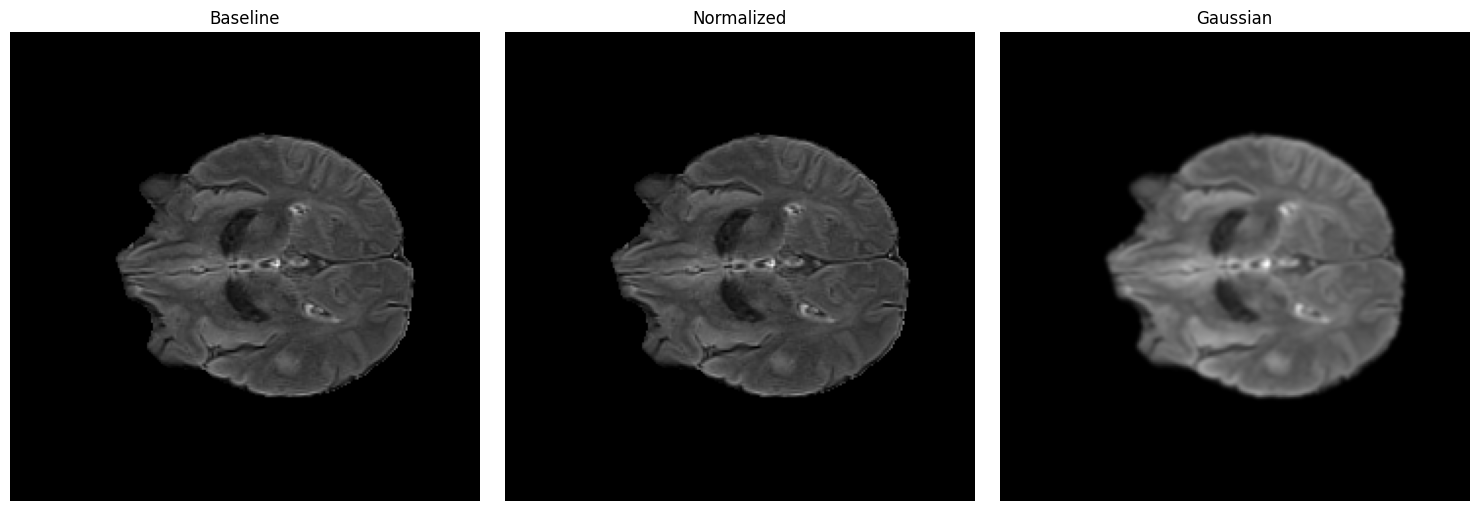

In [14]:
# Displaying one MRI channel before and after preprocessing
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

axes[0].imshow(img_base[:, :, 0], cmap="gray")
axes[0].set_title("Baseline")

axes[1].imshow(img_norm[:, :, 0], cmap="gray")
axes[1].set_title("Normalized")

axes[2].imshow(img_gauss[:, :, 0], cmap="gray")
axes[2].set_title("Gaussian")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

# Visualizing the Ground Truth Mask 

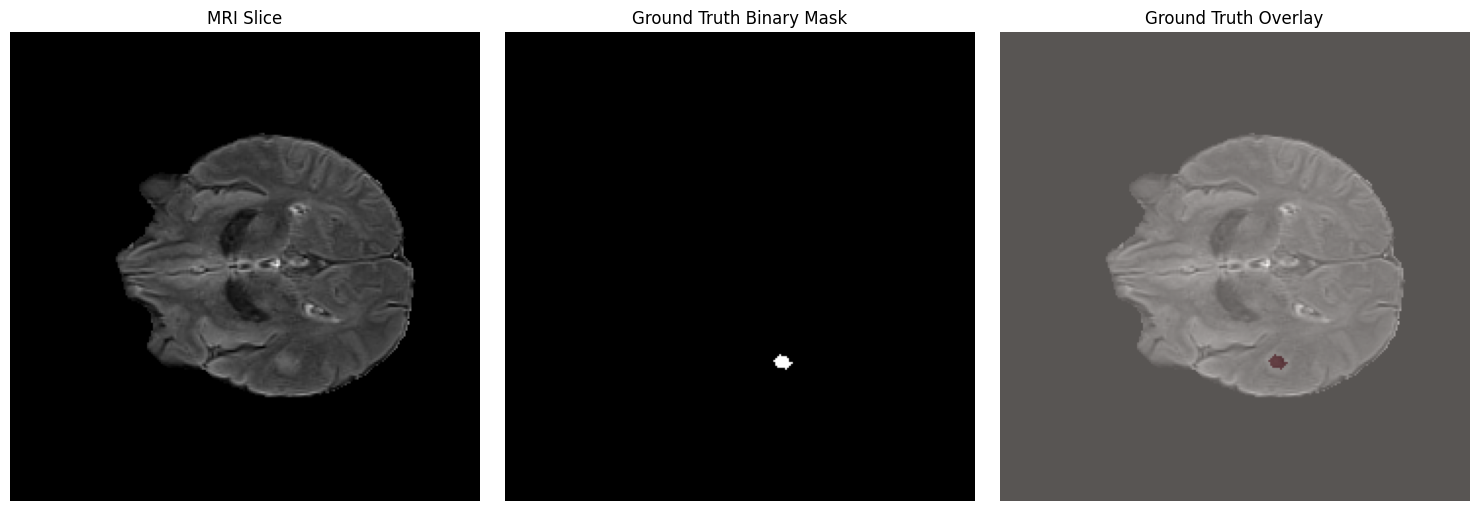

In [15]:
# Showing the MRI slice, binary mask, as well as overlay
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

axes[0].imshow(image[:, :, 0], cmap="gray")
axes[0].set_title("MRI Slice")

axes[1].imshow(binary_mask, cmap="gray")
axes[1].set_title("Ground Truth Binary Mask")

axes[2].imshow(image[:, :, 0], cmap="gray")
axes[2].imshow(binary_mask, cmap="Reds", alpha=0.35)
axes[2].set_title("Ground Truth Overlay")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

# Initial Baseline Segementation Method 

In [16]:
# Segmentation method using thresholding on one channel 
def simple_threshold_seg(image):
    channel = image[:, :, 0]   # Using channel 0 as a starting point here
    threshold = channel.mean()
    pred = (channel > threshold).astype("uint8")
    return pred

# Implementing Evaluation Metrics

In [17]:
# Computing Dice Scores, Sensitivity, and PPV
def compute_metrics(pred, gt):
    pred = pred.astype(np.uint8)
    gt = gt.astype(np.uint8)

    TP = np.sum((pred == 1) & (gt == 1))
    FP = np.sum((pred == 1) & (gt == 0))
    FN = np.sum((pred == 0) & (gt == 1))

    dice = (2 * TP) / (2 * TP + FP + FN + 1e-8)
    sensitivity = TP / (TP + FN + 1e-8)
    ppv = TP / (TP + FP + 1e-8)

    return dice, sensitivity, ppv

# Comparing Baseline Segmentation Across Preprocessing Methods

In [18]:
# Evaluate segmentation performance for each preprocessing pipeline
results = {}

pipelines = {
    "Baseline": preprocess_baseline,
    "Normalized": preprocess_norm,
    "Gaussian": preprocess_gauss
}

for name, preprocess_fn in pipelines.items():
    processed_img = preprocess_fn(image)
    pred_mask = simple_threshold_seg(processed_img)

    dice, sens, ppv = compute_metrics(pred_mask, binary_mask)

    results[name] = {
        "prediction": pred_mask,
        "dice": dice,
        "sensitivity": sens,
        "ppv": ppv
    }

# Print results
for name, result in results.items():
    print(f"{name}: Dice={result['dice']:.4f}, Sens={result['sensitivity']:.4f}, PPV={result['ppv']:.4f}")

Baseline: Dice=0.0059, Sens=1.0000, PPV=0.0029
Normalized: Dice=0.0059, Sens=1.0000, PPV=0.0029
Gaussian: Dice=0.0058, Sens=1.0000, PPV=0.0029


# Visually Comparing Predicted Masks 

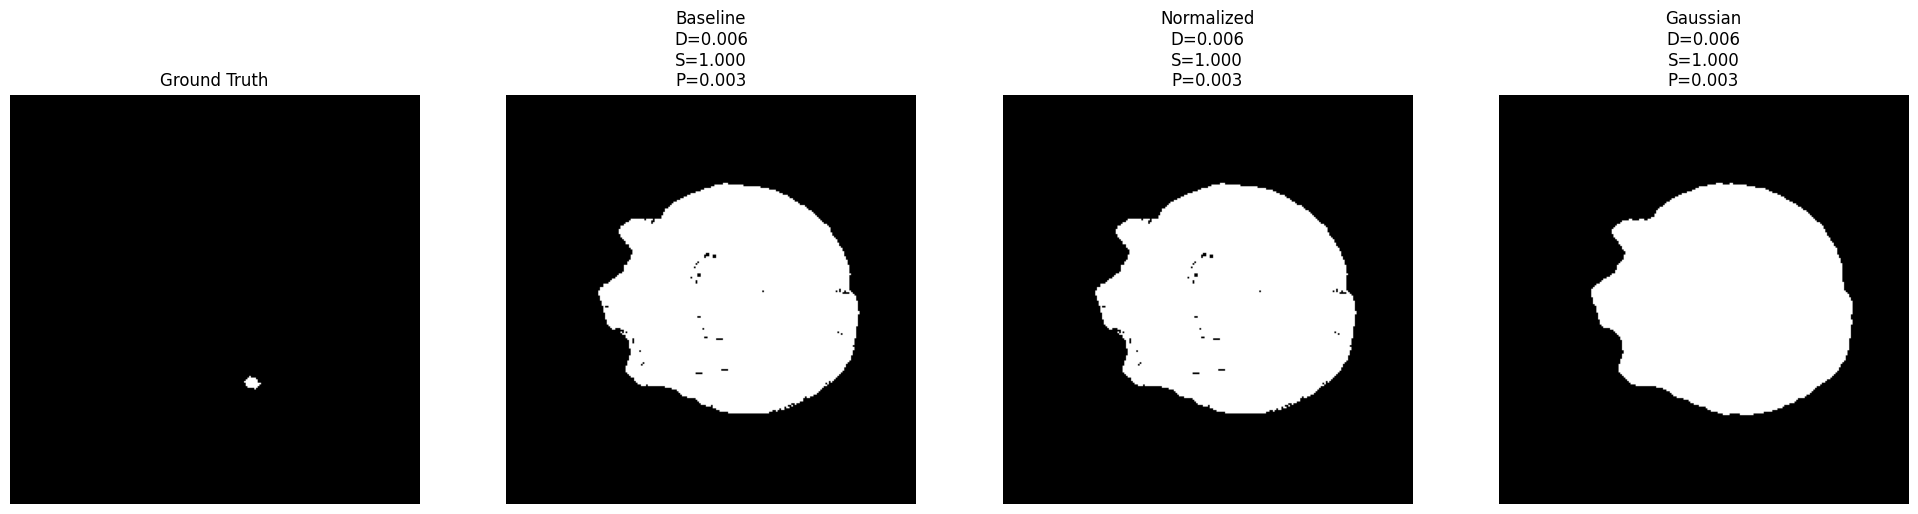

In [19]:
# Displaying predictions with metrics for each preprocessing method
fig, axes = plt.subplots(1, 4, figsize=(20, 5))

axes[0].imshow(binary_mask, cmap="gray")
axes[0].set_title("Ground Truth")
axes[0].axis("off")

axes[1].imshow(results["Baseline"]["prediction"], cmap="gray")
axes[1].set_title(
    f"Baseline\nD={results['Baseline']['dice']:.3f}\nS={results['Baseline']['sensitivity']:.3f}\nP={results['Baseline']['ppv']:.3f}"
)
axes[1].axis("off")

axes[2].imshow(results["Normalized"]["prediction"], cmap="gray")
axes[2].set_title(
    f"Normalized\nD={results['Normalized']['dice']:.3f}\nS={results['Normalized']['sensitivity']:.3f}\nP={results['Normalized']['ppv']:.3f}"
)
axes[2].axis("off")

axes[3].imshow(results["Gaussian"]["prediction"], cmap="gray")
axes[3].set_title(
    f"Gaussian\nD={results['Gaussian']['dice']:.3f}\nS={results['Gaussian']['sensitivity']:.3f}\nP={results['Gaussian']['ppv']:.3f}"
)
axes[3].axis("off")

plt.tight_layout()
plt.show()

# Overlaying Comparisons of Predicted Masks 

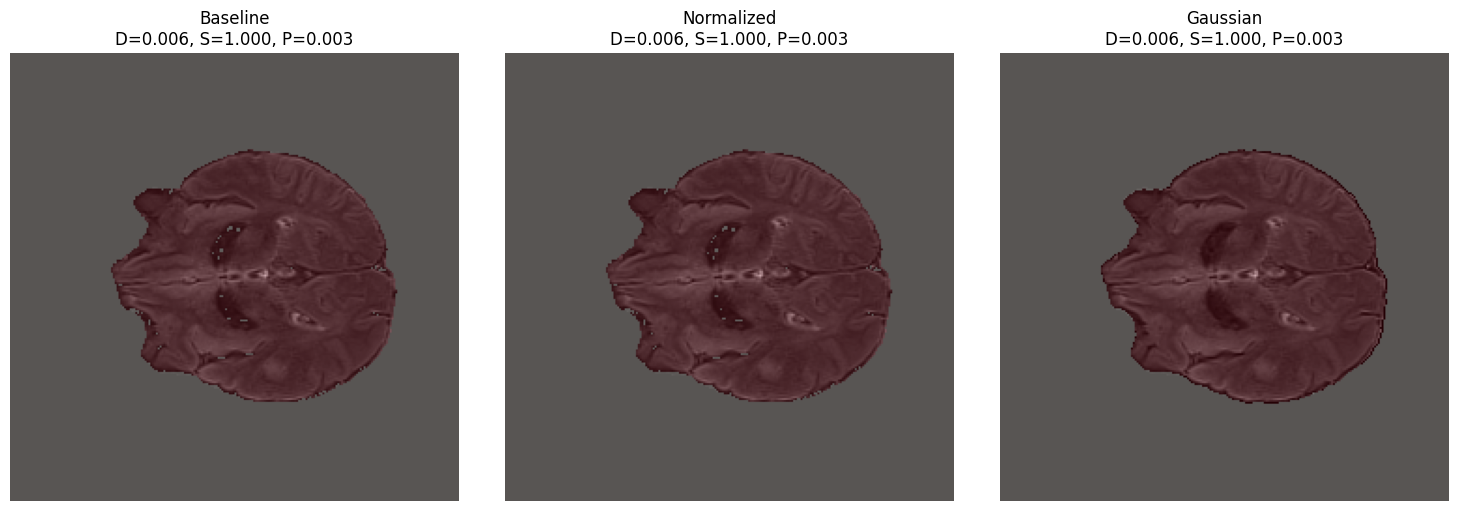

In [20]:
# Overlaying predictions on MRI for better visualization
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

method_names = ["Baseline", "Normalized", "Gaussian"]

for ax, method in zip(axes, method_names):
    ax.imshow(image[:, :, 0], cmap="gray")
    ax.imshow(results[method]["prediction"], cmap="Reds", alpha=0.35)
    ax.set_title(
        f"{method}\nD={results[method]['dice']:.3f}, S={results[method]['sensitivity']:.3f}, P={results[method]['ppv']:.3f}"
    )
    ax.axis("off")

plt.tight_layout()
plt.show()

# Table of Preliminary Results 

In [ ]:
# Printing formatted summary table
print("\nSummary of Results:\n")
print(f"{'Method':<10} {'Dice':<10} {'Sensitivity':<15} {'PPV':<10}")

for name, result in results.items():
    print(f"{name:<10} {result['dice']:<10.4f} {result['sensitivity']:<15.4f} {result['ppv']:<10.4f}")


Summary of Results:

Method     Dice       Sensitivity     PPV       


NameError: name 'results' is not defined